# Higher-Dimensional TF-QKD (Sending-or-Not-Sending) under Gaussian Channel Noise, d = 2–7

Qudit generalisation of sending-or-not-sending (SNS) twin-field QKD, simulated with a single
continuous-variable model across all dimensions on PennyLane's `default.gaussian` device.

- **Encoding:** in each sending round, a weak coherent pulse of amplitude $\alpha$ is placed in one of
  $d-1$ non-vacuum time-bin modes; otherwise the party sends vacuum.
- **Channel noise:** thermal-loss fibre (a thermal mode with mean photon number $\bar n$ mixed in at a
  beamsplitter of transmittance $\eta$) and random phase drift $\delta \sim \mathcal N(0, \sigma_\phi^2)$.
- **Error mechanism:** photon-number discrimination. A symbol error occurs when one of the
  $d-2$ competing modes, populated only by thermal photons, registers at least as many photons
  as the signal mode.
- **Key rate:** $r_d(Q) = \log_2 d - 2H_d(Q)$ per detection event, with total rate $R = p_{\rm click}\, r_d(Q)$.

At $d = 2$ there are no competing modes, so this error mechanism is absent. The model therefore
does not apply at $d = 2$, and $d = 2$ appears only in the QSER plots as a reference line.

In [ ]:
#Install
!pip install pennylane scipy -q

In [ ]:
#Import

import numpy as np
import matplotlib.pyplot as plt
import pennylane as qml
from scipy.optimize import brentq
from scipy.stats import poisson as sp_poisson
import warnings
warnings.filterwarnings("ignore")

print(f"PennyLane {qml.__version__} | NumPy {np.__version__}")

PennyLane 0.45.1 | NumPy 2.5.3


## 1. Parameters

In [ ]:
# Physical parameters
ALPHA   = 2.0    # coherent-state amplitude (mean photon number ALPHA^2 = 4)
ETA     = 0.5    # one-way channel transmittance per arm
EPSILON = 0.12   # SNS sending probability per party per round
DIMS    = [2, 3, 4, 5, 6, 7]
DIMS_KR = [d for d in DIMS if d >= 3]   # dimensions where the error model applies

# Monte Carlo parameters
N_ROUNDS = 150_000   # rounds per trial
N_TRIALS = 20        # independent trials per noise point
N_LEVELS = 12        # noise levels per sweep

# Noise sweep ranges
NBAR_MAX        = 1.5    # maximum thermal photon number
SIGMA_PHI_MAX   = 0.50   # maximum phase-drift standard deviation (rad)
NBAR_PHASE_BASE = 0.30   # background thermal noise during the phase-drift sweep

# Okabe-Ito colour-blind-safe palette
COLORS = {2: "#0072B2", 3: "#E69F00", 4: "#009E73", 5: "#CC79A7",
          6: "#D55E00", 7: "#56B4E9", 8: "#8E44AD", 9: "#7F8C8D"}

DEV = qml.device("default.gaussian", wires=4, shots=None)

print(f"ALPHA={ALPHA}, ETA={ETA}, EPSILON={EPSILON}, DIMS={DIMS}")
print(f"N_ROUNDS={N_ROUNDS:,}, N_TRIALS={N_TRIALS}, N_LEVELS={N_LEVELS}")
print(f"Thermal sweep: nbar in [0, {NBAR_MAX}]")
print(f"Phase sweep:   sigma_phi in [0, {SIGMA_PHI_MAX}] rad on background nbar={NBAR_PHASE_BASE}")

ALPHA=2.0, ETA=0.5, EPSILON=0.12, DIMS=[2, 3, 4, 5, 6, 7]
N_ROUNDS=150,000, N_TRIALS=20, N_LEVELS=12
Thermal sweep: nbar in [0, 1.5]
Phase sweep:   sigma_phi in [0, 0.5] rad on background nbar=0.3


## 2. Gaussian channel circuit

Wires: 0 = Alice signal, 1 = Alice thermal environment, 2 = Bob signal, 3 = Bob thermal environment.

1. Coherent-state preparation on each signal mode.
2. Thermal-loss channel: each signal mode mixes with a `ThermalState` at a beamsplitter with
   $\cos^2\theta = \eta$.
3. Phase drift on Bob's mode via `Rotation`.
4. Charlie's 50:50 beamsplitter.

The 2×2 transfer matrix $U$ is recovered from the output quadrature means
$\langle\hat a\rangle = (\langle \hat x\rangle + i\langle \hat p\rangle)/2$ for unit inputs on each arm.
The thermal contribution to each quadrature has standard deviation $\sqrt{\bar n(1-\eta)/2}$.

In [ ]:
@qml.qnode(DEV)
def gaussian_quadrature(ax, ap, bx, bp, theta_loss, nbar, phi_drift, out_wire, quad):
    qml.CoherentState(ax, ap, wires=0)
    qml.ThermalState(nbar, wires=1)
    qml.Beamsplitter(theta_loss, 0, wires=[0, 1])      # thermal-loss channel, Alice arm
    qml.CoherentState(bx, bp, wires=2)
    qml.ThermalState(nbar, wires=3)
    qml.Beamsplitter(theta_loss, 0, wires=[2, 3])      # thermal-loss channel, Bob arm
    qml.Rotation(phi_drift, wires=2)                   # phase drift
    qml.Beamsplitter(np.pi / 4, 0, wires=[0, 2])       # Charlie's 50:50 beamsplitter
    if quad == "X":
        return qml.expval(qml.QuadX(out_wire))
    return qml.expval(qml.QuadP(out_wire))


def extract_transfer_matrix(eta, nbar, phi_drift=0.0):
    """Return the 2x2 complex transfer matrix U and the thermal quadrature std."""
    theta_loss = float(np.arccos(np.sqrt(max(float(eta), 1e-10))))
    U = np.zeros((2, 2), dtype=complex)
    for in_idx, (ax, bx) in enumerate([(1.0, 0.0), (0.0, 1.0)]):
        for out_idx, ow in enumerate([0, 2]):
            x = float(gaussian_quadrature(ax, 0.0, bx, 0.0, theta_loss, float(nbar), float(phi_drift), ow, "X"))
            p = float(gaussian_quadrature(ax, 0.0, bx, 0.0, theta_loss, float(nbar), float(phi_drift), ow, "P"))
            U[out_idx, in_idx] = (x + 1j * p) / 2.0
    sigma_th = float(np.sqrt(max(float(nbar), 0.0) * (1.0 - float(eta)) / 2.0))
    return U, sigma_th


U_ideal, _      = extract_transfer_matrix(1.0, 0.0)
U_lossy, _      = extract_transfer_matrix(ETA, 0.0)
U_drift, _      = extract_transfer_matrix(ETA, 0.0, phi_drift=np.pi / 4)
_, sigma_th_chk = extract_transfer_matrix(ETA, 0.1)

print("Transfer-matrix validation:")
print(f"  Ideal (eta=1):      |U[1,0]|^2 = {abs(U_ideal[1, 0])**2:.4f}  (expected 0.5000)")
print(f"  Lossy (eta={ETA}):    |U[1,0]|^2 = {abs(U_lossy[1, 0])**2:.4f}  (expected {ETA * 0.5:.4f})")
print(f"  Thermal (nbar=0.1): sigma_th   = {sigma_th_chk:.5f}  (expected {np.sqrt(0.1 * (1 - ETA) / 2):.5f})")

Transfer-matrix validation:
  Ideal (eta=1):      |U[1,0]|^2 = 0.5000  (expected 0.5000)
  Lossy (eta=0.5):    |U[1,0]|^2 = 0.2500  (expected 0.2500)
  Thermal (nbar=0.1): sigma_th   = 0.15811  (expected 0.15811)


### Transfer-matrix heatmaps
Power transfer $|U_{ij}|^2$ from each input arm to each output port of Charlie's beamsplitter.
Loss scales every entry by $\eta$. Phase drift changes only the phase of $U$, so the power
split stays the same while the interference between the arms changes.

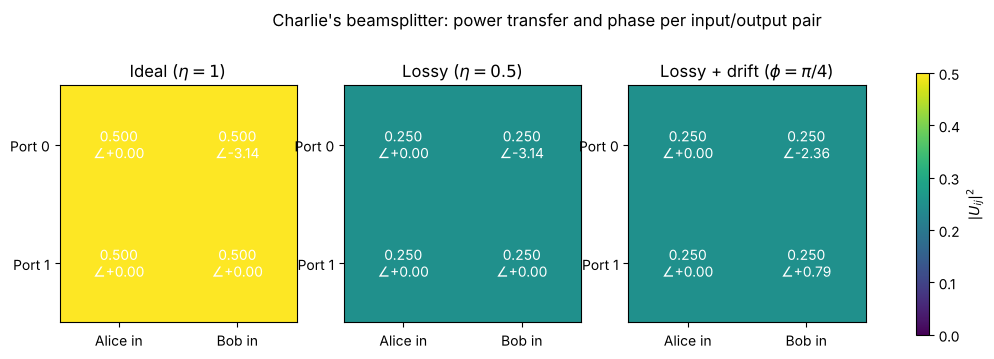

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, U, title in [(axes[0], U_ideal, r"Ideal ($\eta=1$)"),
                     (axes[1], U_lossy, rf"Lossy ($\eta={ETA}$)"),
                     (axes[2], U_drift, rf"Lossy + drift ($\phi=\pi/4$)")]:
    im = ax.imshow(np.abs(U)**2, vmin=0, vmax=0.5, cmap="viridis")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{abs(U[i, j])**2:.3f}\n∠{np.angle(U[i, j]):+.2f}",
                    ha="center", va="center", color="white", fontsize=10)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Alice in", "Bob in"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Port 0", "Port 1"])
    ax.set_title(title)
fig.colorbar(im, ax=axes, label=r"$|U_{ij}|^2$", shrink=0.85)
plt.suptitle("Charlie's beamsplitter: power transfer and phase per input/output pair")
plt.show()

## 3. Analytical QSER and key rate

Signal mode mean photon number $\lambda = \eta|\alpha|^2 + \bar n(1-\eta)$; each competing mode has
$\mu = \bar n(1-\eta)$. Conditioned on a click ($k \ge 1$ signal photons):

$$Q(d) = \frac{\sum_{k\ge1} P_\lambda(k)\,\bigl[1 - F_\mu(k-1)^{\,d-2}\bigr]}{1 - e^{-\lambda}}$$

$d$-ary entropy: $H_d(x) = -x\log_2\frac{x}{d-1} - (1-x)\log_2(1-x)$.

Key rate per detection event: $r_d(Q) = \log_2 d - 2H_d(Q)$. Zero-rate threshold $e^*(d)$: root of $r_d(e)=0$.

In [ ]:
def qser_formula(d, alpha, eta, nbar, kmax=60):
    """Analytical QSER from photon-number discrimination against d-2 thermal competing modes."""
    n_sig_mean = eta * alpha**2
    n_thermal  = nbar * (1.0 - eta)
    n_total    = n_sig_mean + n_thermal
    n_comp     = d - 2
    p_click    = 1.0 - np.exp(-n_total)
    if p_click < 1e-12:
        return 0.0
    p_error_and_click = 0.0
    for sig_k in range(1, kmax + 1):
        p_sig = sp_poisson.pmf(sig_k, n_total)
        if p_sig < 1e-12:
            continue
        p_all_comp_lt = sp_poisson.cdf(sig_k - 1, n_thermal)**n_comp if n_thermal > 1e-12 else 1.0
        p_error_and_click += p_sig * (1.0 - p_all_comp_lt)
    return float(p_error_and_click / p_click)


def H_d(x, d):
    """d-ary Shannon entropy, clipped at its maximum x = (d-1)/d."""
    if x <= 0:
        return 0.0
    x = min(float(x), (d - 1) / d)
    t1 = -x * np.log2(x / (d - 1)) if x > 0 else 0.0
    t2 = -(1 - x) * np.log2(1 - x) if x < 1 else 0.0
    return t1 + t2


def key_rate_raw(d, qser):
    """Unclamped key rate r_d(Q) = log2(d) - 2 H_d(Q)."""
    return np.log2(d) - 2 * H_d(qser, d)


def key_rate_from_qser(d, qser):
    """Secret key rate per detection event, clamped at zero."""
    return float(max(key_rate_raw(d, qser), 0.0))


def zero_rate_threshold(d):
    """QSER at which r_d(Q) = 0 (Brent's method)."""
    return brentq(lambda e: key_rate_raw(d, e), 1e-6, 0.9 * (d - 1) / d)


thresholds = {d: zero_rate_threshold(d) for d in DIMS}
print("Zero-rate thresholds e*(d):")
for d in DIMS:
    print(f"  d={d}: e* = {thresholds[d]*100:.2f}%")

print("\nAnalytical QSER (%):")
print(f"{'nbar':>6}" + "".join(f"{'d='+str(d):>9}" for d in DIMS))
for nb in [0.0, 0.1, 0.3, 0.5, 0.8, 1.0, 1.5]:
    print(f"{nb:6.2f}" + "".join(f"{qser_formula(d, ALPHA, ETA, nb)*100:9.3f}" for d in DIMS))

Zero-rate thresholds e*(d):
  d=2: e* = 11.00%
  d=3: e* = 15.95%
  d=4: e* = 18.93%
  d=5: e* = 20.99%
  d=6: e* = 22.52%
  d=7: e* = 23.72%

Analytical QSER (%):
  nbar      d=2      d=3      d=4      d=5      d=6      d=7
  0.00    0.000    0.000    0.000    0.000    0.000    0.000
  0.10    0.000    1.515    2.958    4.333    5.642    6.890
  0.30    0.000    4.270    7.987   11.227   14.057   16.533
  0.50    0.000    6.704   12.090   16.445   19.994   22.911
  0.80    0.000    9.856   16.999   22.294   26.322   29.476
  1.00    0.000   11.679   19.665   25.340   29.548   32.809
  1.50    0.000   15.474   24.903   31.183   35.729   39.251


### Error mechanism: photon-number distributions
Photon-count distributions for the signal mode and for one thermal competing mode. An error
occurs whenever the largest of the $d-2$ competing counts is at least the signal count, so the
overlap grows with both $\bar n$ and the number of competing modes.

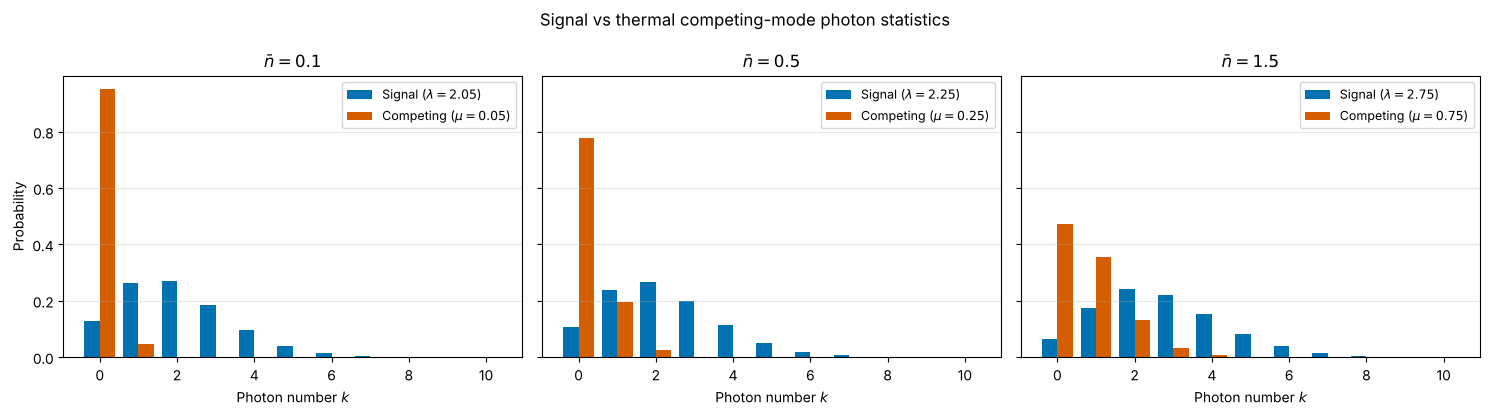

In [ ]:
k = np.arange(0, 11)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, nb in zip(axes, [0.1, 0.5, 1.5]):
    lam = ETA * ALPHA**2 + nb * (1 - ETA)
    mu  = nb * (1 - ETA)
    ax.bar(k - 0.2, sp_poisson.pmf(k, lam), 0.4, color="#0072B2", label=fr"Signal ($\lambda={lam:.2f}$)")
    ax.bar(k + 0.2, sp_poisson.pmf(k, mu),  0.4, color="#D55E00", label=fr"Competing ($\mu={mu:.2f}$)")
    ax.set_title(fr"$\bar n = {nb}$")
    ax.set_xlabel("Photon number $k$")
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3, axis="y")
axes[0].set_ylabel("Probability")
plt.suptitle("Signal vs thermal competing-mode photon statistics")
plt.tight_layout()
plt.show()

### QSER heatmap over dimension and thermal noise
The colour shows the analytical QSER. Each row is one dimension, and the dashed contour marks
where that dimension reaches its own zero-rate threshold $e^*(d)$.

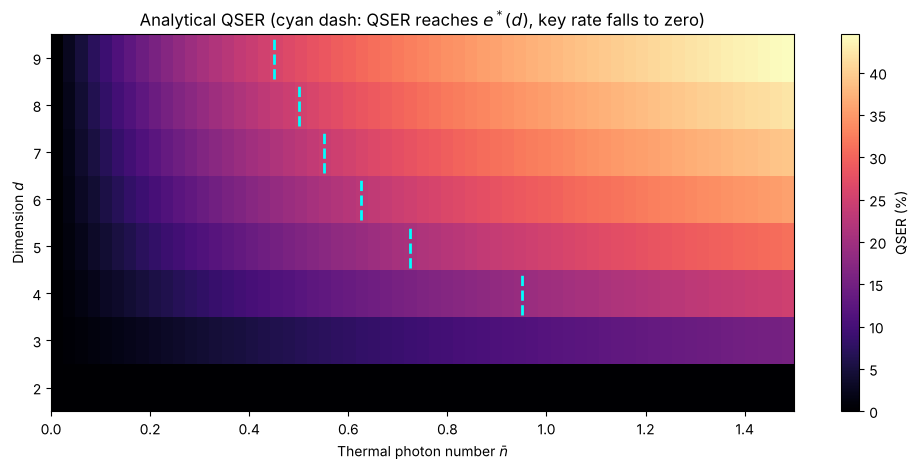

In [ ]:
nbar_grid = np.linspace(0.0, NBAR_MAX, 61)
dims_grid = list(range(2, 10))
qser_grid = np.array([[qser_formula(d, ALPHA, ETA, nb) for nb in nbar_grid] for d in dims_grid])
th_grid   = {d: zero_rate_threshold(d) for d in dims_grid}

fig, ax = plt.subplots(figsize=(10, 4.8))
im = ax.imshow(qser_grid * 100, aspect="auto", origin="lower", cmap="magma",
               extent=[nbar_grid[0], nbar_grid[-1], dims_grid[0] - 0.5, dims_grid[-1] + 0.5])
for i, d in enumerate(dims_grid):
    if d < 3:
        continue
    above = np.where(qser_grid[i] >= th_grid[d])[0]
    if len(above):
        ax.plot([nbar_grid[above[0]]] * 2, [d - 0.45, d + 0.45], color="cyan", lw=2, ls="--")
fig.colorbar(im, ax=ax, label="QSER (%)")
ax.set_xlabel(r"Thermal photon number $\bar n$")
ax.set_ylabel("Dimension $d$")
ax.set_yticks(dims_grid)
ax.set_title("Analytical QSER (cyan dash: QSER reaches $e^*(d)$, key rate falls to zero)")
plt.tight_layout()
plt.show()

## 4. Monte Carlo simulation engine

Per round, Alice and Bob each send vacuum with probability $1-\epsilon$, or a pulse in one of
$d-1$ modes with probability $\epsilon/(d-1)$ each. Key rounds are those where exactly one party sends.

- Signal-mode photon count: Poisson with mean $\eta\alpha^2\cos^2\delta + \bar n(1-\eta)$.
- Rounds with zero signal photons produce no click and are discarded.
- Thermal error: the largest of $d-2$ competing Poisson($\bar n(1-\eta)$) counts is at least the signal count.
- Intercept-resend: Eve replaces each non-vacuum symbol from Alice with a uniformly random
  non-vacuum symbol. The expected QSER is $\tfrac12\cdot\tfrac{d-2}{d-1}$.

In [ ]:
def simulate_one_trial(d, seed, alpha, eta, nbar, sigma_phi=0.0, eve_present=False):
    """One Monte Carlo trial; returns simulated and analytical QSER and key rates."""
    rng = np.random.default_rng(seed)
    n_sig_mean = eta * alpha**2
    n_thermal  = nbar * (1.0 - eta)

    # Symbol choice: 0 = vacuum, 1..d-1 = pulse in that time-bin mode
    n_sym = d - 1
    probs = [1.0 - EPSILON] + [EPSILON / n_sym] * n_sym
    a = rng.choice(d, size=N_ROUNDS, p=probs)
    b = rng.choice(d, size=N_ROUNDS, p=probs)

    # Intercept-resend on Alice's non-vacuum rounds
    if eve_present:
        eve_resend = rng.integers(1, d, N_ROUNDS)
        a_sent = np.where(a != 0, eve_resend, 0)
    else:
        a_sent = a.copy()

    # Key rounds: exactly one party sends
    alice_only = (a_sent != 0) & (b == 0)
    bob_only   = (a_sent == 0) & (b != 0)
    n_errors = 0
    n_clicks = 0

    for orig_choices, sent_choices, n_rounds in [
        (a[alice_only], a_sent[alice_only], int(alice_only.sum())),
        (b[bob_only],   b[bob_only],        int(bob_only.sum())),
    ]:
        if n_rounds == 0:
            continue

        # Signal-mode mean photon number, reduced by phase drift
        if sigma_phi > 0.0:
            drift   = rng.normal(0.0, sigma_phi, n_rounds)
            n_sig_r = n_sig_mean * np.cos(drift)**2 + n_thermal
        else:
            n_sig_r = np.full(n_rounds, n_sig_mean + n_thermal)

        counts_sig = rng.poisson(n_sig_r)
        clicked = counts_sig >= 1
        n_ok = int(clicked.sum())
        n_clicks += n_ok
        if n_ok == 0:
            continue

        # Symbol mismatch introduced by Eve
        if eve_present:
            mismatch = sent_choices[clicked] != orig_choices[clicked]
            n_errors += int(mismatch.sum())
            correct_idx = ~mismatch
        else:
            correct_idx = np.ones(n_ok, dtype=bool)
        n_correct = int(correct_idx.sum())

        # Thermal error: a competing mode outscores the signal mode
        if n_correct > 0 and n_sym > 1 and n_thermal > 1e-12:
            cs_ok     = counts_sig[clicked][correct_idx]
            comp      = rng.poisson(n_thermal, (n_correct, n_sym - 1))
            n_errors += int((comp.max(axis=1) >= cs_ok).sum())

    qser_sim   = n_errors / n_clicks if n_clicks > 0 else 0.0
    click_rate = n_clicks / N_ROUNDS
    qser_form  = qser_formula(d, alpha, eta, nbar)
    return dict(
        qser_sim=qser_sim, qser_formula=qser_form,
        key_rate_sim=click_rate * key_rate_from_qser(d, qser_sim),
        key_rate_formula=click_rate * key_rate_from_qser(d, qser_form),
        click_rate=click_rate, n_key=n_clicks,
    )


print("Check 1: noiseless channel, no Eve (QSER = 0 expected)")
print(f"{'d':>3}  {'QSER_sim':>10}  {'QSER_formula':>13}  {'n_key':>8}")
for d in DIMS:
    r = simulate_one_trial(d, seed=0, alpha=ALPHA, eta=ETA, nbar=0.0)
    print(f"{d:3d}  {r['qser_sim']*100:9.4f}%  {r['qser_formula']*100:12.4f}%  {r['n_key']:8d}")

print("\nCheck 2: thermal noise nbar=0.5, no Eve")
for d in DIMS:
    r = simulate_one_trial(d, seed=1, alpha=ALPHA, eta=ETA, nbar=0.5)
    print(f"  d={d}: QSER_sim={r['qser_sim']*100:.3f}%  QSER_formula={r['qser_formula']*100:.3f}%")

print("\nCheck 3: intercept-resend, nbar=0 (expected (1/2)(d-2)/(d-1))")
for d in DIMS:
    r = simulate_one_trial(d, seed=2, alpha=ALPHA, eta=ETA, nbar=0.0, eve_present=True)
    print(f"  d={d}: QSER_sim={r['qser_sim']*100:.2f}%  expected={0.5*(d-2)/(d-1)*100:.2f}%")

Check 1: noiseless channel, no Eve (QSER = 0 expected)
  d    QSER_sim   QSER_formula     n_key
  2     0.0000%        0.0000%     27265
  3     0.0000%        0.0000%     27265
  4     0.0000%        0.0000%     27265
  5     0.0000%        0.0000%     27265
  6     0.0000%        0.0000%     27265
  7     0.0000%        0.0000%     27265

Check 2: thermal noise nbar=0.5, no Eve
  d=2: QSER_sim=0.000%  QSER_formula=0.000%
  d=3: QSER_sim=6.678%  QSER_formula=6.704%
  d=4: QSER_sim=11.971%  QSER_formula=12.090%
  d=5: QSER_sim=16.480%  QSER_formula=16.445%
  d=6: QSER_sim=20.296%  QSER_formula=19.994%
  d=7: QSER_sim=22.727%  QSER_formula=22.911%

Check 3: intercept-resend, nbar=0 (expected (1/2)(d-2)/(d-1))
  d=2: QSER_sim=0.00%  expected=0.00%
  d=3: QSER_sim=25.30%  expected=25.00%
  d=4: QSER_sim=33.54%  expected=33.33%
  d=5: QSER_sim=37.74%  expected=37.50%
  d=6: QSER_sim=40.27%  expected=40.00%
  d=7: QSER_sim=41.75%  expected=41.67%


## 5. Noise sweeps
Thermal sweep: $\bar n \in [0, 1.5]$ with no phase drift. Phase sweep: $\sigma_\phi \in [0, 0.5]$ rad
on a fixed background $\bar n = 0.3$. Each point averages `N_TRIALS` independent trials.

In [ ]:
nbar_levels      = np.linspace(0.0, NBAR_MAX, N_LEVELS)
sigma_phi_levels = np.linspace(0.0, SIGMA_PHI_MAX, N_LEVELS)


def run_sweep(nbar_levels, sigma_phi_levels, eve_present=False, dims=DIMS):
    """Thermal and phase-drift sweeps; returns per-d, per-level statistics."""
    results   = {d: {"thermal": [], "phase": []} for d in dims}
    base_seed = 6000 if eve_present else 5000

    for noise_type, levels in [("thermal", nbar_levels), ("phase", sigma_phi_levels)]:
        for li, noise_val in enumerate(levels):
            nb = noise_val if noise_type == "thermal" else NBAR_PHASE_BASE
            sp = noise_val if noise_type == "phase" else 0.0
            for d in dims:
                qsers, krs, crs = [], [], []
                for trial in range(N_TRIALS):
                    seed = base_seed + d * 10000 + li * 200 + trial
                    r = simulate_one_trial(d, seed, ALPHA, ETA, nb, sp, eve_present)
                    qsers.append(r["qser_sim"])
                    krs.append(r["key_rate_sim"])
                    crs.append(r["click_rate"])
                qf = qser_formula(d, ALPHA, ETA, nb)
                results[d][noise_type].append(dict(
                    noise_val=float(noise_val),
                    mean_qser=float(np.mean(qsers)), std_qser=float(np.std(qsers)),
                    mean_kr=float(np.mean(krs)),     std_kr=float(np.std(krs)),
                    qser_formula=qf,
                    kr_formula=float(np.mean(crs)) * key_rate_from_qser(d, qf),
                ))
    return results


print("Running no-Eve sweep ...")
results_no_eve = run_sweep(nbar_levels, sigma_phi_levels, eve_present=False)
print("Running Eve sweep ...")
results_eve = run_sweep(nbar_levels, sigma_phi_levels, eve_present=True)
print("Done.")

Running no-Eve sweep ...


Running Eve sweep ...


Done.


## 6. Results tables

In [ ]:
print("Thermal sweep, no Eve:")
for d in DIMS:
    print(f"\nd={d}  (e* = {thresholds[d]*100:.2f}%)")
    for row in results_no_eve[d]["thermal"]:
        print(f"  nbar={row['noise_val']:.4f}  Q_sim={row['mean_qser']*100:5.2f}%  "
              f"std={row['std_qser']*100:4.2f}%  Q_form={row['qser_formula']*100:5.2f}%  "
              f"R(Q_sim)={row['mean_kr']:.4f}  R(Q_form)={row['kr_formula']:.4f}")

print("\nCoefficient of variation (std/mean) of QSER across trials, %:")
for noise_type, levels, lbl in [("thermal", nbar_levels, "nbar"), ("phase", sigma_phi_levels, "sigma_phi")]:
    print(f"\n  {noise_type} sweep")
    print(f"  {lbl:>10}" + "".join(f"   d={d} Q%    CV%" for d in DIMS_KR))
    for i in range(N_LEVELS):
        line = f"  {levels[i]:10.4f}"
        for d in DIMS_KR:
            r = results_no_eve[d][noise_type][i]
            cv = r["std_qser"] / max(r["mean_qser"], 1e-9) * 100
            line += f"  {r['mean_qser']*100:8.3f}  {cv:5.1f}"
        print(line)

print("\nQSER (%), no Eve vs Eve, thermal sweep:")
print(f"{'nbar':>6}" + "".join(f"  d{d} noEve   d{d} Eve" for d in DIMS))
for i in range(N_LEVELS):
    line = f"{nbar_levels[i]:6.3f}"
    for d in DIMS:
        line += f"  {results_no_eve[d]['thermal'][i]['mean_qser']*100:8.3f}  {results_eve[d]['thermal'][i]['mean_qser']*100:7.3f}"
    print(line)

print("\nQSER gap between consecutive dimensions (percentage points), thermal sweep:")
print(f"{'nbar':>6}" + "".join(f"   d{DIMS_KR[k]}-d{DIMS_KR[k-1]}" for k in range(1, len(DIMS_KR))))
for i in range(N_LEVELS):
    line = f"{nbar_levels[i]:6.3f}"
    for k in range(1, len(DIMS_KR)):
        hi, lo = DIMS_KR[k], DIMS_KR[k - 1]
        line += f"   {(results_no_eve[hi]['thermal'][i]['mean_qser'] - results_no_eve[lo]['thermal'][i]['mean_qser'])*100:7.3f}"
    print(line)

Thermal sweep, no Eve:

d=2  (e* = 11.00%)
  nbar=0.0000  Q_sim= 0.00%  std=0.00%  Q_form= 0.00%  R(Q_sim)=0.1825  R(Q_form)=0.1825
  nbar=0.1364  Q_sim= 0.00%  std=0.00%  Q_form= 0.00%  R(Q_sim)=0.1846  R(Q_form)=0.1846
  nbar=0.2727  Q_sim= 0.00%  std=0.00%  Q_form= 0.00%  R(Q_sim)=0.1867  R(Q_form)=0.1867
  nbar=0.4091  Q_sim= 0.00%  std=0.00%  Q_form= 0.00%  R(Q_sim)=0.1878  R(Q_form)=0.1878
  nbar=0.5455  Q_sim= 0.00%  std=0.00%  Q_form= 0.00%  R(Q_sim)=0.1895  R(Q_form)=0.1895
  nbar=0.6818  Q_sim= 0.00%  std=0.00%  Q_form= 0.00%  R(Q_sim)=0.1910  R(Q_form)=0.1910
  nbar=0.8182  Q_sim= 0.00%  std=0.00%  Q_form= 0.00%  R(Q_sim)=0.1924  R(Q_form)=0.1924
  nbar=0.9545  Q_sim= 0.00%  std=0.00%  Q_form= 0.00%  R(Q_sim)=0.1933  R(Q_form)=0.1933
  nbar=1.0909  Q_sim= 0.00%  std=0.00%  Q_form= 0.00%  R(Q_sim)=0.1948  R(Q_form)=0.1948
  nbar=1.2273  Q_sim= 0.00%  std=0.00%  Q_form= 0.00%  R(Q_sim)=0.1956  R(Q_form)=0.1956
  nbar=1.3636  Q_sim= 0.00%  std=0.00%  Q_form= 0.00%  R(Q_sim)=0.1

## 7. Figures

In [ ]:
plt.rcParams.update({"figure.dpi": 150, "savefig.dpi": 300, "font.size": 11})
LKW = dict(fontsize=9.5, facecolor="#ffffff", framealpha=1.0, edgecolor="#999999")


def style_axis(ax, title, xlabel, ylabel, ylim=None):
    ax.set_title(title, fontsize=13, pad=10)
    ax.set_xlabel(xlabel, fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.grid(True, color="#cccccc", alpha=0.6, lw=0.6)
    ax.set_axisbelow(True)
    if ylim:
        ax.set_ylim(ylim)

### QSER vs thermal noise (solid: simulated, dashed: analytical)

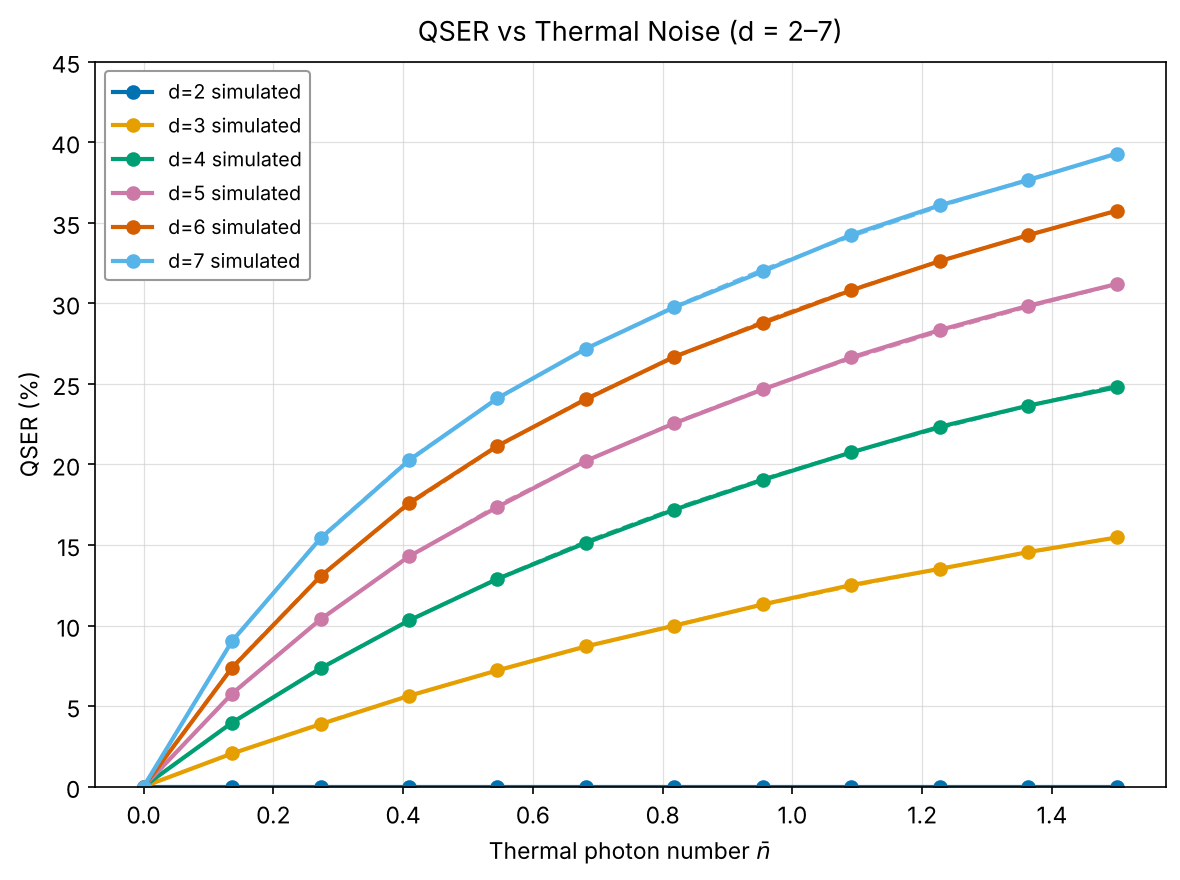

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
style_axis(ax, "QSER vs Thermal Noise (d = 2–7)", r"Thermal photon number $\bar{n}$", "QSER (%)", [0, 45])
for d in DIMS:
    mu = [r["mean_qser"] * 100 for r in results_no_eve[d]["thermal"]]
    qf = [r["qser_formula"] * 100 for r in results_no_eve[d]["thermal"]]
    ax.plot(nbar_levels, mu, color=COLORS[d], lw=2.0, marker="o", ms=6, label=f"d={d} simulated")
    ax.plot(nbar_levels, qf, color=COLORS[d], lw=1.5, ls="--", alpha=0.85)
ax.legend(**LKW, loc="upper left")
plt.tight_layout()
plt.show()

### Secret key rate vs thermal noise (d = 3–7)

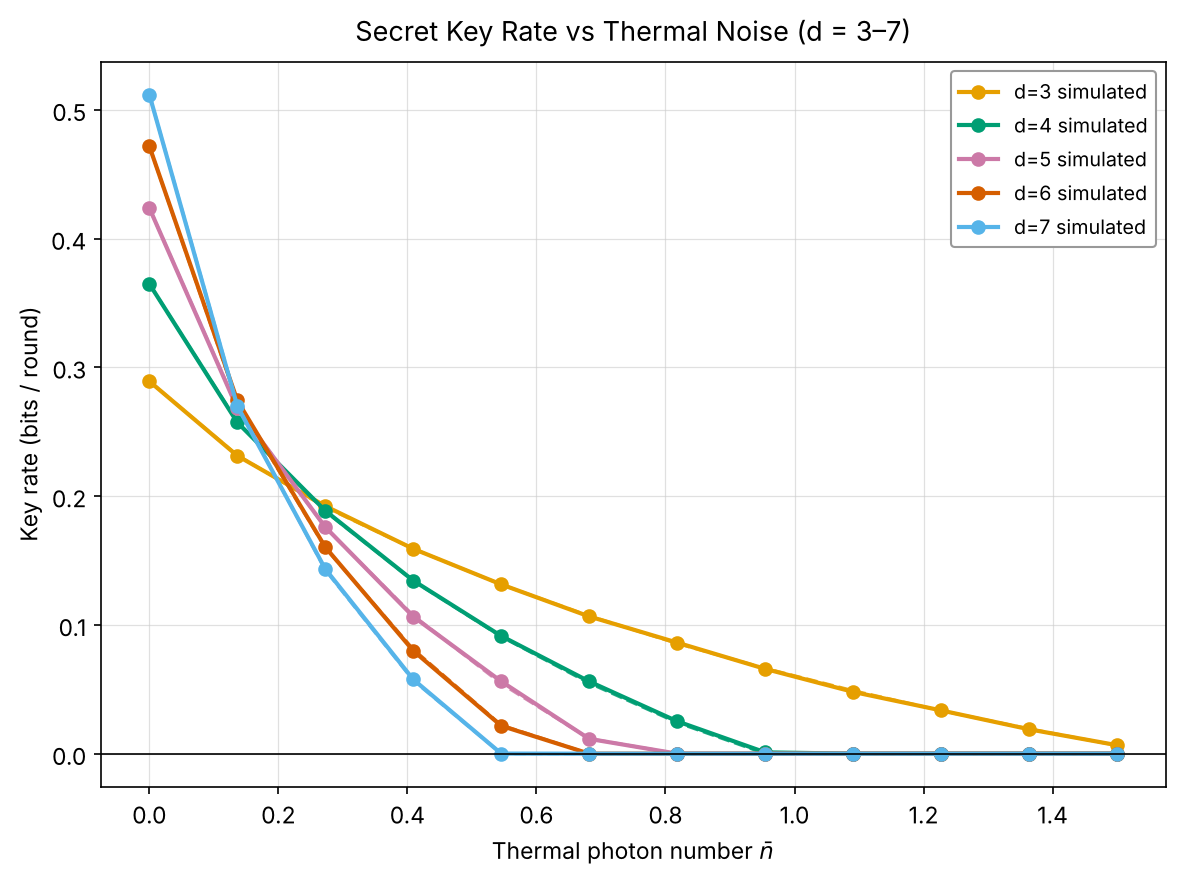

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
style_axis(ax, "Secret Key Rate vs Thermal Noise (d = 3–7)",
           r"Thermal photon number $\bar{n}$", "Key rate (bits / round)")
for d in DIMS_KR:
    mu = [r["mean_kr"] for r in results_no_eve[d]["thermal"]]
    kf = [r["kr_formula"] for r in results_no_eve[d]["thermal"]]
    ax.plot(nbar_levels, mu, color=COLORS[d], lw=2.0, marker="o", ms=6, label=f"d={d} simulated")
    ax.plot(nbar_levels, kf, color=COLORS[d], lw=1.5, ls="--", alpha=0.85)
ax.axhline(0, color="#000000", lw=0.8)
ax.legend(**LKW, loc="upper right")
plt.tight_layout()
plt.show()

### QSER vs phase drift

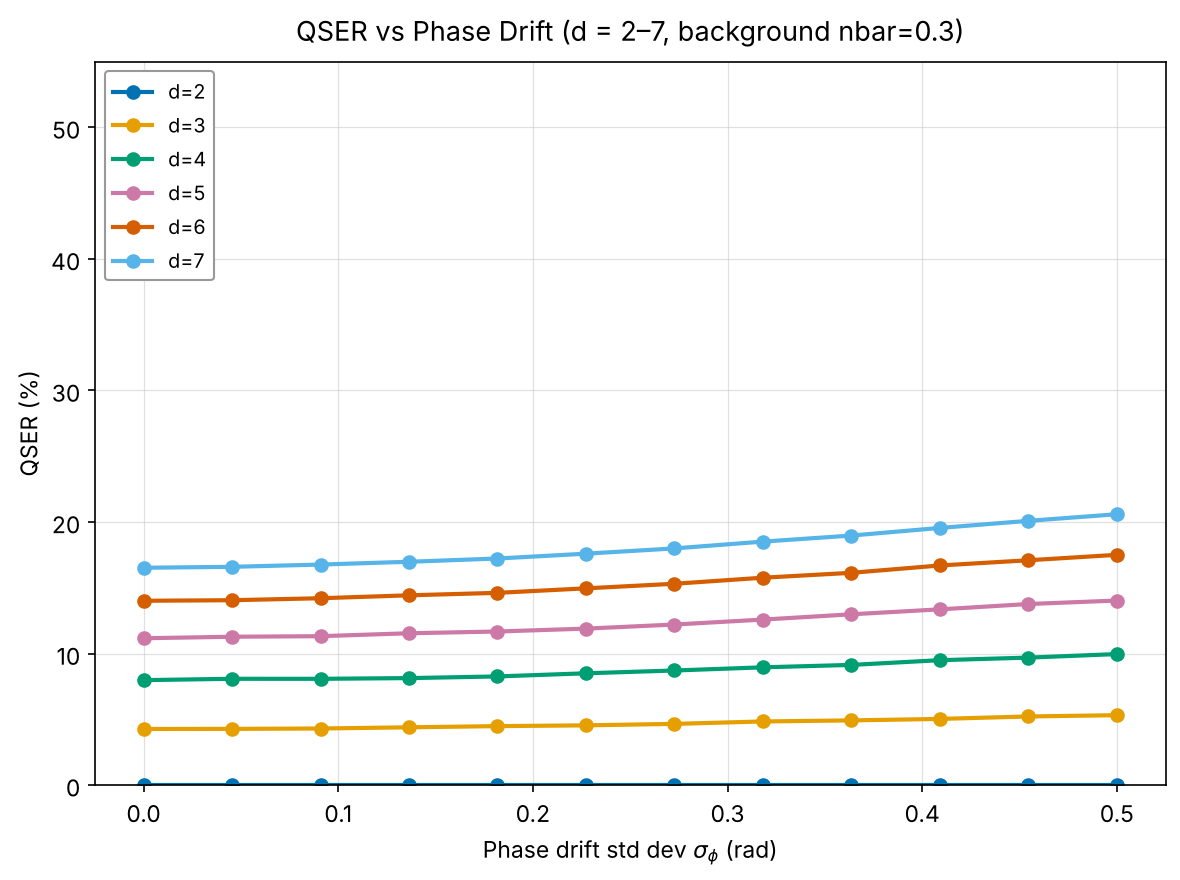

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
style_axis(ax, f"QSER vs Phase Drift (d = 2–7, background nbar={NBAR_PHASE_BASE})",
           r"Phase drift std dev $\sigma_\phi$ (rad)", "QSER (%)", [0, 55])
for d in DIMS:
    mu = [r["mean_qser"] * 100 for r in results_no_eve[d]["phase"]]
    ax.plot(sigma_phi_levels, mu, color=COLORS[d], lw=2.0, marker="o", ms=6, label=f"d={d}")
ax.legend(**LKW, loc="upper left")
plt.tight_layout()
plt.show()

### Secret key rate vs phase drift (d = 3–7)

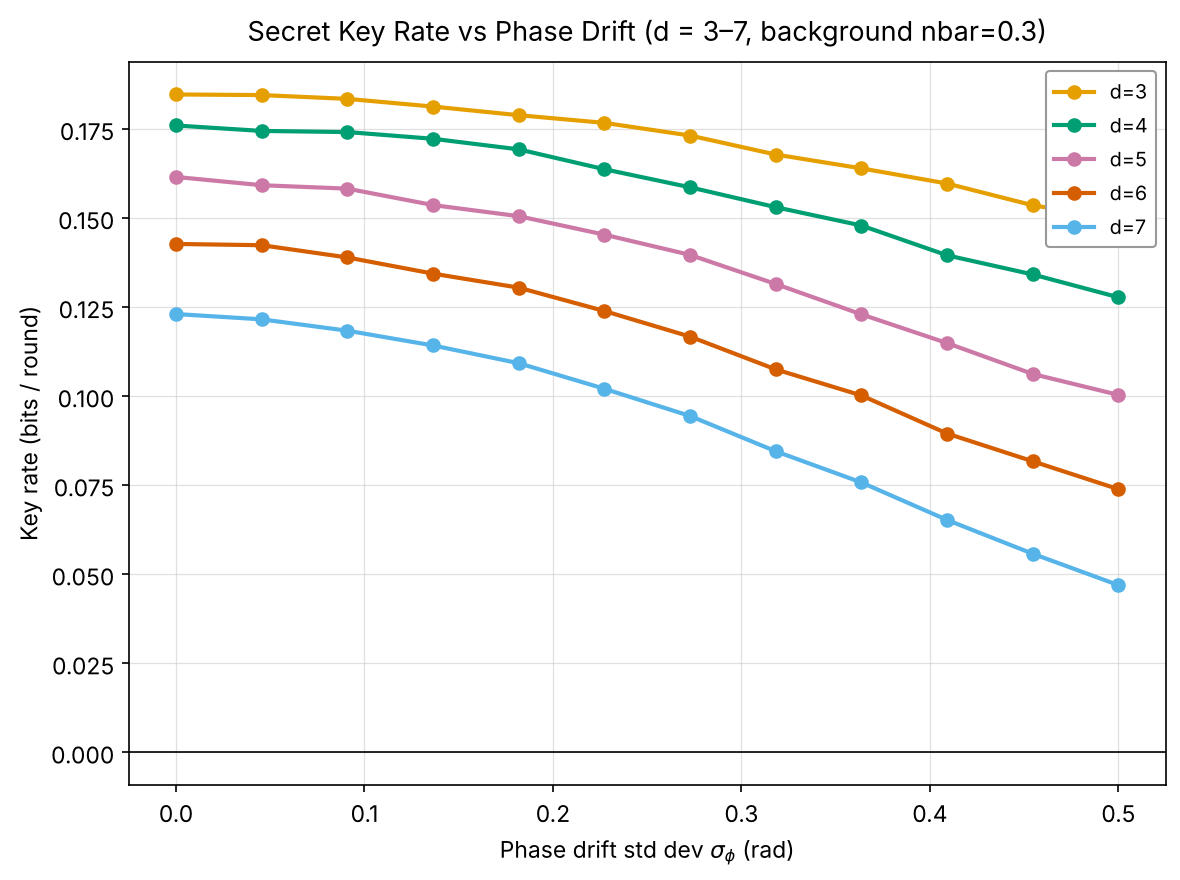

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
style_axis(ax, f"Secret Key Rate vs Phase Drift (d = 3–7, background nbar={NBAR_PHASE_BASE})",
           r"Phase drift std dev $\sigma_\phi$ (rad)", "Key rate (bits / round)")
for d in DIMS_KR:
    mu = [r["mean_kr"] for r in results_no_eve[d]["phase"]]
    ax.plot(sigma_phi_levels, mu, color=COLORS[d], lw=2.0, marker="o", ms=6, label=f"d={d}")
ax.axhline(0, color="#000000", lw=0.8)
ax.legend(**LKW, loc="upper right")
plt.tight_layout()
plt.show()

### Intercept-resend vs no eavesdropper (solid: no Eve, dashed: Eve)

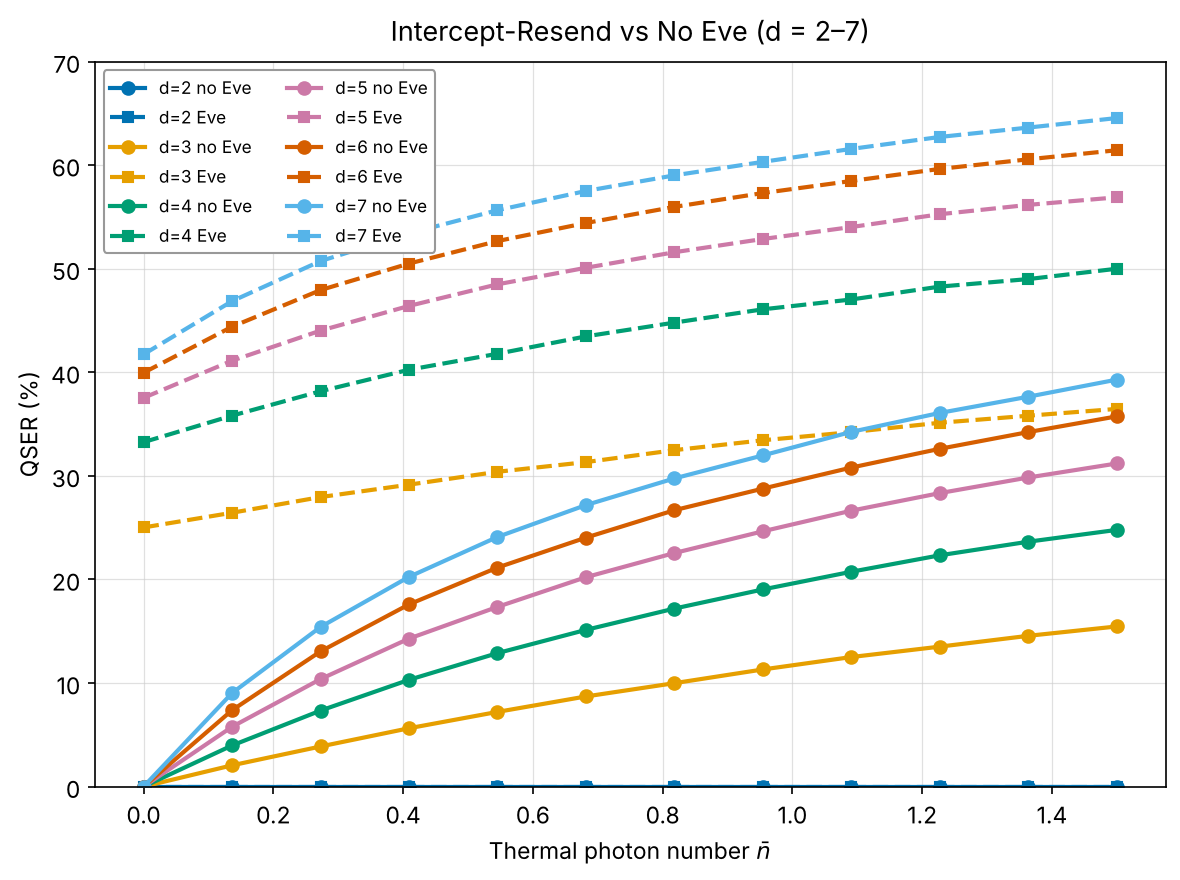

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
style_axis(ax, "Intercept-Resend vs No Eve (d = 2–7)",
           r"Thermal photon number $\bar{n}$", "QSER (%)", [0, 70])
for d in DIMS:
    mn = [r["mean_qser"] * 100 for r in results_no_eve[d]["thermal"]]
    me = [r["mean_qser"] * 100 for r in results_eve[d]["thermal"]]
    ax.plot(nbar_levels, mn, color=COLORS[d], lw=2.0, marker="o", ms=6, label=f"d={d} no Eve")
    ax.plot(nbar_levels, me, color=COLORS[d], lw=2.0, ls="--", marker="s", ms=5, label=f"d={d} Eve")
ax.legend(fontsize=8.3, ncol=2, loc="upper left", framealpha=1.0, edgecolor="#999999")
plt.tight_layout()
plt.show()

### Diminishing returns: QSER gap between consecutive dimensions (d = 3–7)

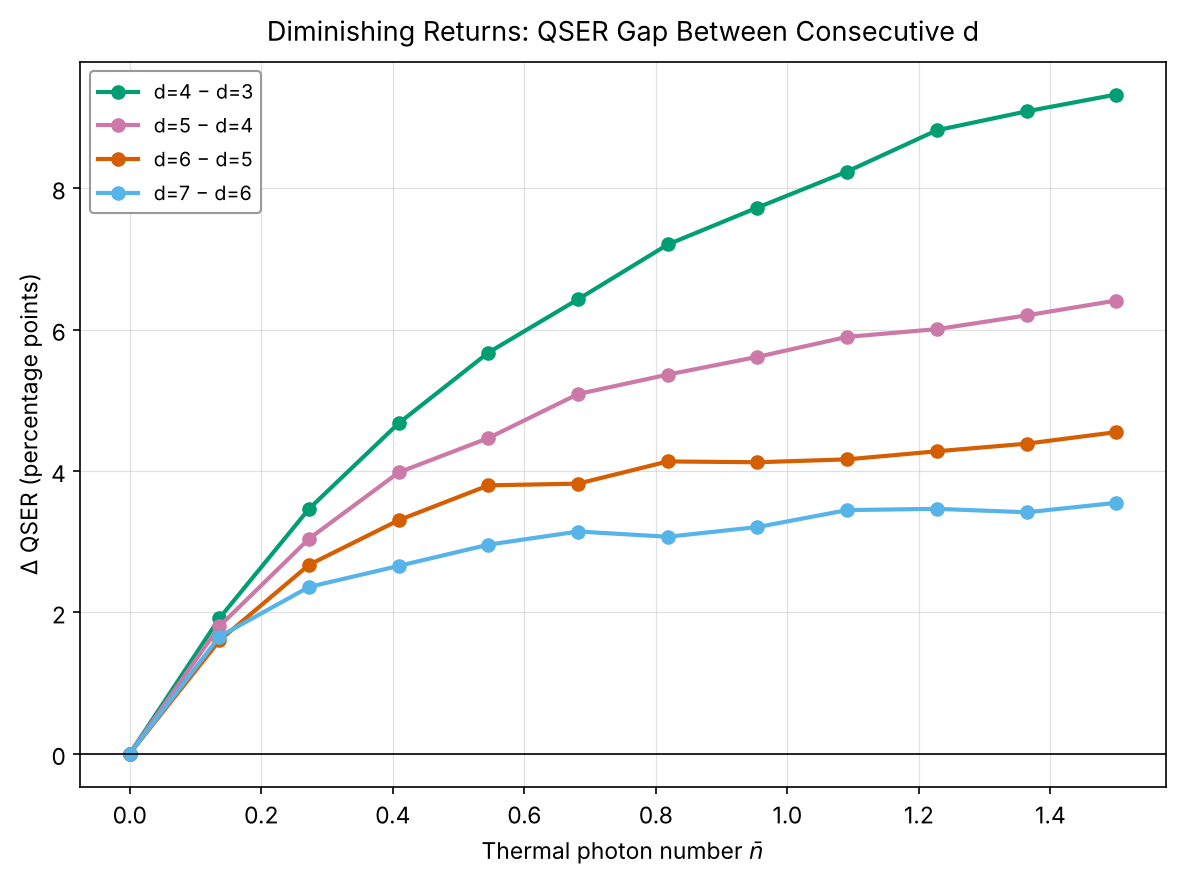

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
style_axis(ax, "Diminishing Returns: QSER Gap Between Consecutive d",
           r"Thermal photon number $\bar{n}$", "Δ QSER (percentage points)")
for k in range(1, len(DIMS_KR)):
    hi, lo = DIMS_KR[k], DIMS_KR[k - 1]
    diff = [(results_no_eve[hi]["thermal"][i]["mean_qser"]
             - results_no_eve[lo]["thermal"][i]["mean_qser"]) * 100 for i in range(N_LEVELS)]
    ax.plot(nbar_levels, diff, color=COLORS[hi], lw=2.0, marker="o", ms=6, label=f"d={hi} − d={lo}")
ax.axhline(0, color="#000000", lw=0.8)
ax.legend(**LKW, loc="upper left")
plt.tight_layout()
plt.show()

## 8. Rate-optimal dimension and security margin (analytical, d = 3–12)

TF-QKD has no $1/d$ measurement penalty, and $p_{\rm click}$ does not depend on $d$. The rate-optimal
dimension at a given $\bar n$ is therefore $\arg\max_d\, r_d\bigl(Q(d,\bar n)\bigr)$.

- Zero-rate thermal noise $\bar n^*(d)$: root of $Q(d, \bar n) = e^*(d)$.
- Security margin: $Q_{\rm Eve} - e^*(d)$ with $Q_{\rm Eve} = \tfrac12\cdot\tfrac{d-2}{d-1}$.

In [ ]:
DIMS_EXT = list(range(3, 13))
th_ext = {d: zero_rate_threshold(d) for d in DIMS_EXT}

print("Zero-rate thermal noise nbar*(d):")
for d in range(3, 10):
    nbar_star = brentq(lambda nb: qser_formula(d, ALPHA, ETA, nb) - th_ext[d], 1e-4, 5.0)
    print(f"  d={d}: nbar* = {nbar_star:.3f}")

print("\nRate-optimal dimension vs thermal noise:")
nb_fine = np.arange(0.0, 0.40, 0.005)
prev = None
for nb in nb_fine:
    rates  = [key_rate_from_qser(d, qser_formula(d, ALPHA, ETA, nb)) for d in DIMS_EXT]
    best_d = DIMS_EXT[int(np.argmax(rates))]
    if best_d != prev:
        print(f"  from nbar = {nb:.3f}: optimum d = {best_d}  "
              f"(QSER at optimum = {qser_formula(best_d, ALPHA, ETA, nb)*100:.2f}%)")
        prev = best_d

print("\nSecurity margin Q_Eve - e*(d):")
print(f"{'d':>3}  {'e* (%)':>8}  {'Q_Eve (%)':>10}  {'margin (pp)':>12}  {'increment':>10}")
prev_margin = None
for d in range(3, 10):
    q_eve  = 0.5 * (d - 2) / (d - 1)
    margin = (q_eve - th_ext[d]) * 100
    inc    = "" if prev_margin is None else f"{margin - prev_margin:+.2f}"
    print(f"{d:>3}  {th_ext[d]*100:8.2f}  {q_eve*100:10.2f}  {margin:12.2f}  {inc:>10}")
    prev_margin = margin

Zero-rate thermal noise nbar*(d):
  d=3: nbar* = 1.572
  d=4: nbar* = 0.942
  d=5: nbar* = 0.724
  d=6: nbar* = 0.607


  d=7: nbar* = 0.531
  d=8: nbar* = 0.477
  d=9: nbar* = 0.437

Rate-optimal dimension vs thermal noise:
  from nbar = 0.000: optimum d = 12  (QSER at optimum = 0.00%)


  from nbar = 0.070: optimum d = 11  (QSER at optimum = 8.43%)
  from nbar = 0.075: optimum d = 10  (QSER at optimum = 8.09%)
  from nbar = 0.085: optimum d = 9  (QSER at optimum = 8.03%)


  from nbar = 0.095: optimum d = 8  (QSER at optimum = 7.73%)
  from nbar = 0.110: optimum d = 7  (QSER at optimum = 7.49%)


  from nbar = 0.130: optimum d = 6  (QSER at optimum = 7.12%)
  from nbar = 0.160: optimum d = 5  (QSER at optimum = 6.62%)


  from nbar = 0.195: optimum d = 4  (QSER at optimum = 5.48%)


  from nbar = 0.255: optimum d = 3  (QSER at optimum = 3.68%)



Security margin Q_Eve - e*(d):
  d    e* (%)   Q_Eve (%)   margin (pp)   increment
  3     15.95       25.00          9.05            
  4     18.93       33.33         14.40       +5.35
  5     20.99       37.50         16.51       +2.11
  6     22.52       40.00         17.48       +0.97
  7     23.72       41.67         17.94       +0.46
  8     24.70       42.86         18.15       +0.21
  9     25.52       43.75         18.23       +0.08


### Key-rate heatmap and optimal-dimension ladder
The colour shows $r_d$ per detection event. White dots mark the rate-optimal dimension at each
$\bar n$. As thermal noise grows, the optimum moves down to lower dimensions.

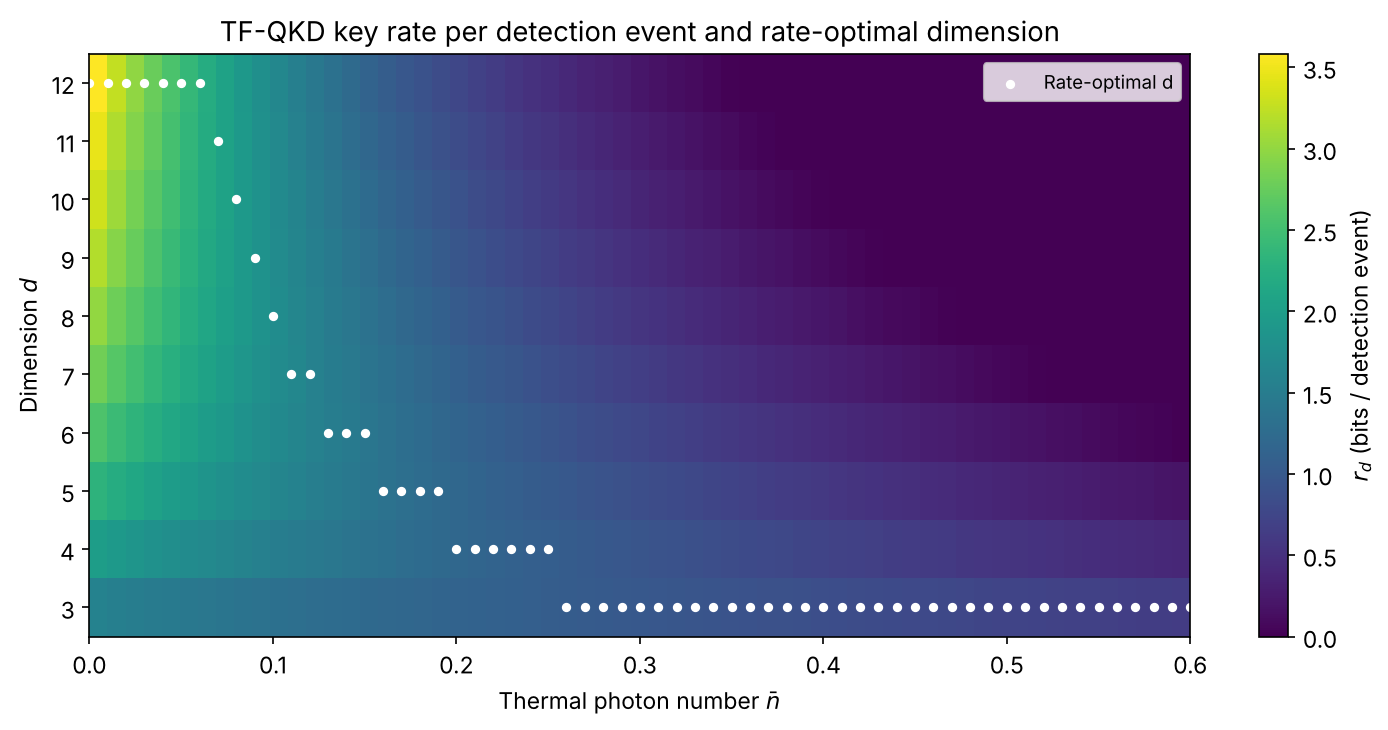

In [ ]:
nb_hm   = np.linspace(0.0, 0.6, 61)
rate_hm = np.array([[key_rate_from_qser(d, qser_formula(d, ALPHA, ETA, nb)) for nb in nb_hm]
                    for d in DIMS_EXT])
best_hm = [DIMS_EXT[int(np.argmax(rate_hm[:, j]))] for j in range(len(nb_hm))]

fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(rate_hm, aspect="auto", origin="lower", cmap="viridis",
               extent=[nb_hm[0], nb_hm[-1], DIMS_EXT[0] - 0.5, DIMS_EXT[-1] + 0.5])
ax.scatter(nb_hm, best_hm, color="white", s=12, label="Rate-optimal d")
fig.colorbar(im, ax=ax, label=r"$r_d$ (bits / detection event)")
ax.set_xlabel(r"Thermal photon number $\bar n$")
ax.set_ylabel("Dimension $d$")
ax.set_yticks(DIMS_EXT)
ax.set_title("TF-QKD key rate per detection event and rate-optimal dimension")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()